In [2]:
import numpy as np
import pandas as pd
import mne
import h5py
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn.plotting import plot_markers
from mne_bids import BIDSPath

from himalaya.backend import set_backend, get_backend
from himalaya.ridge import RidgeCV
from himalaya.scoring import correlation_score

from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import re
import mne
import numpy as np
from mne_bids import BIDSPath
from nilearn import datasets, image
from scipy.spatial import KDTree
from collections import Counter

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from nilearn import plotting


# Electrode Selection

In [4]:
transcript_path = "stimuli/podcast_transcript.csv"

df = pd.read_csv(transcript_path)
df.head(20)

,word,start,end
0,Act,3.710,3.790
1,"one,",3.990,4.190
2,monkey,4.651,4.931
3,in,4.951,5.011
4,the,5.051,5.111
5,middle.,5.151,5.391
6,So,6.592,6.732
7,there's,6.752,6.912
8,some,6.892,7.052
9,places,7.072,7.342


In [6]:
df.shape

(5136, 3)

In [7]:
glove_path = 'glove.6B.50d.txt'

In [8]:
#create the glove model based on our glove file in (above; in the current directory)
def load_glove_to_dict(file_path):
    glove_dict = {}
    print(f"Loading {file_path}...")

    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # Each line looks like: word 0.123 0.456 ...
            values = line.split()
            word = values[0]
            # Convert the numbers into a numpy array
            vector = np.asarray(values[1:], dtype='float32')
            glove_dict[word] = vector

    print(f"Done! {len(glove_dict)} words loaded.")
    return glove_dict


# Load the model 
glove_model = load_glove_to_dict(glove_path)



Loading glove.6B.50d.txt...
Done! 400000 words loaded.


In [9]:
# ── Build GloVe embeddings for the transcript ──────────────────────────────

def clean_word(w):
    """This transforms each word, so it's ready to be found in it's glove embedding. 
    It does Lowercase + normalize apostrophes + strip punctuation."""
    w = str(w).lower()
    # Normalize curly apostrophes to straight ones for GloVe compatibility
    w = re.sub(r"[’‘’ʻ]", "'", w)
    # Strip punctuation but keep internal apostrophes (don't strip ')
    return w.strip(" .,!?;:\"()-[]")

# Update the dataframe with the better cleanup
df["word_clean"] = df["word"].apply(clean_word)

# Define words that should be excluded as fillers
# Words that don't carry semantic meaning/ sounds made in the transcript
EXCLUDE_FILLERS = {'ch', 'hm', 'mhm', 'mm','uh', 'um'}

# ── Assign embeddings, track OOV words ─────────────────────────────────────
embeddings_list = []   # GloVe vectors for words IN the vocab
words_in_glove  = []   # corresponding words (clean)
word_indices    = []   # original row indices in df
oov_words       = []   # words NOT found in GloVe (or fillers)

for idx, row in df.iterrows():
    w = row["word_clean"]

    # Filtered word check + GloVe presence check
    if w in EXCLUDE_FILLERS or w not in glove_model:
        oov_words.append(w)
    else:
        # If it passes both (not filler AND in GloVe), keep it
        embeddings_list.append(glove_model[w])
        words_in_glove.append(w)
        word_indices.append(idx)

# ── Stack into matrix ───────────────────────────────────────────────────────
X_glove = np.stack(embeddings_list).astype("float32")  # (n_words_found, 50)

# ── Build a filtered dataframe aligned to the embeddings ───────────────────
df_glove = df.loc[word_indices].reset_index(drop=False)   # keep original idx as column

print("=" * 50)
print(f"Total words in transcript : {len(df)}")
print(f"Words WITH GloVe embedding: {len(words_in_glove)}  ← Target: ~4,843")
print(f"Words WITHOUT (OOV/Fill)  : {len(oov_words)}")
print(f"X_glove shape             : {X_glove.shape}")
print("=" * 50)
print(f"\nFirst 10 OOV/Filtered words: {oov_words[:10]}")
print(f"\ndf_glove head:")
df_glove.head(8)

Total words in transcript : 5136
Words WITH GloVe embedding: 4867  ← Target: ~4,843
Words WITHOUT (OOV/Fill)  : 269
X_glove shape             : (4867, 50)

First 10 OOV/Filtered words: ["there's", 'chivvis', "i'd", 'mm', 'uh', 'uh', "they'd", "it's", 'ch', 'ch']

df_glove head:


,index,word,start,end,word_clean
0,0,Act,3.710,3.790,act
1,1,"one,",3.990,4.190,one
2,2,monkey,4.651,4.931,monkey
3,3,in,4.951,5.011,in
4,4,the,5.051,5.111,the
5,5,middle.,5.151,5.391,middle
6,6,So,6.592,6.732,so
7,8,some,6.892,7.052,some


In [10]:
a = oov_words
len(a)

269

In [11]:
df_glove.shape

(4867, 5)

In [12]:
df.shape
df_glove.shape
X_glove.shape

(4867, 50)

In [ ]:
# Current folder directory
bids_root = "add path where your BIDS dataset is stored"

All channels: 235
Left hemisphere electrodes : 191
Right hemisphere electrodes: 44

raw now has 191 channels


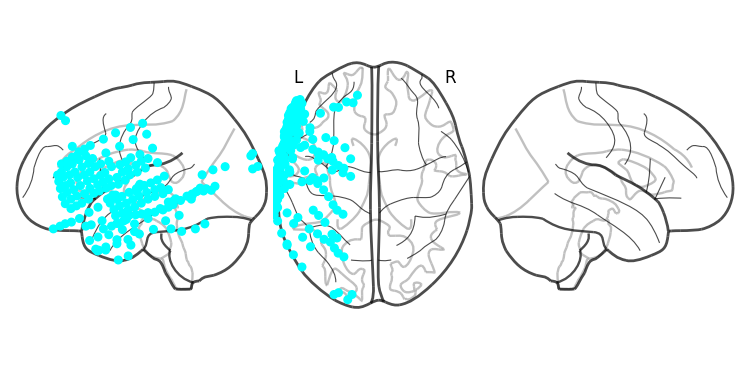

In [ ]:
#This is the process of electrode selection
#This cell and the ones underneath were re-run for every patient 

########################### Step 1: raw = current patient neural data #######################
subj_id = "03"

# ── 1. Load raw ─────────────────────────────────────────────────────────────
file_path = BIDSPath(
    root=f"{bids_root}derivatives/ecogprep",
    subject=f"{subj_id}", task="podcast", datatype="ieeg",
    description="highgamma", suffix="ieeg", extension=".fif"
)
raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)
print(f"All channels: {len(raw.ch_names)}")

# ── 2. Get MNI coordinates for all channels ─────────────────────────────────
ch2loc = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000

# ── 3. Left hemisphere = negative x in MNI space ────────────────────────────
#This ensures that we are only selecting electrodes from the left hemisphere, patient 01, was excluded since they only had electrodes in the right
lh_mask = coords_mm[:, 0] < 0

selected_ch_names = [ch for ch, keep in zip(raw.ch_names, lh_mask) if keep]

print(f"Left hemisphere electrodes : {lh_mask.sum()}")
print(f"Right hemisphere electrodes: {(~lh_mask).sum()}")

# ── 4. Apply to raw ──────────────────────────────────────────────────────────
raw = raw.copy().pick(selected_ch_names)
print(f"\nraw now has {len(raw.ch_names)} channels")

# ── 5. Sanity check — plot and verify all x < 0 ─────────────────────────────
ch2loc = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
coords = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000

values = np.zeros(len(coords))
plot_markers(values, coords,
             node_size=30, display_mode='lzr', alpha=1,
             node_cmap='cool', colorbar=False, node_vmin=0, node_vmax=1)

In [18]:
raw

<Raw | sub-03_task-podcast_desc-highgamma_ieeg.fif, 191 x 921600 (1800.0 s), ~240 KiB, data not loaded>

In [19]:
df_glove.shape

(4867, 5)

In [20]:
##################### Step 2: Build events ONLY from words that have a GloVe embedding 


sfreq_orig = raw.info['sfreq']   # 512 Hz

events = np.zeros((len(df_glove), 3), dtype=int)
# since df_glove already has the exact words we need (those in glove), we just get the start times for all those rows
# multiple them by the sampling frequency for MNE processing 
events[:, 0] = (df_glove['start'].values * sfreq_orig).astype(int)


print(f"Events built from GloVe words only: {events.shape}")
print(f"  → {len(df_glove)} words going into MNE (already OOV-filtered)") #OOV = out of vocabulary words

Events built from GloVe words only: (4867, 3)
  → 4867 words going into MNE (already OOV-filtered)


In [ ]:
# Create epochs (MNE will drop bad recordings internally)
# This is why these cells are repeated for each patient, since MNE will find a different number of EPOCHS to drop, and once it drops it, according to it's documentation, it will drop it for all of the electrodes for that patient
# If we did for all patients at once, that would mean we would lose data that would still be valuable 
# So we repeat the analysis instead
epochs = mne.Epochs(
    raw,
    events,
    tmin=-2.0,
    tmax=2.0,
    baseline=None,
    proj=False,
    event_id=None,
    preload=True,
    event_repeated="merge",
)
print(f"Epochs before resample : {epochs._data.shape}")
print(f"  Dropped by MNE       : {len(df_glove) - len(epochs)} words")
print(f"  epochs.selection     : indices into df_glove for kept words")

Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1376341187.py:2: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


6 bad epochs dropped
Epochs before resample : (4861, 188, 2049)
  Dropped by MNE       : 6 words
  epochs.selection     : indices into df_glove for kept words


In [ ]:
############################################ Step 3: Window averaging 
# Following the papper, keep 512 Hz but turn it into 161 time lags from -2000ms to +2000ms in 25ms steps, by averaging within 200ms windows around each lag center
# This reduced noise and makes curves smoother 

sfreq  = epochs.info['sfreq']          # 512 Hz/ samples/ lages
times  = epochs.times                  # shape (2049,) in seconds, e.g. -2.0 ... +2.0 #2049 because 512 *4 seconds, this is the total brain activity we have

# Define 161 lag centers: -2000ms to +2000ms in 25ms steps
#for every 25ms step
lag_centers_sec = np.arange(-2.0, 2.0 + 0.025/2, 0.025)  # 161 values
print(f"Number of lag centers: {len(lag_centers_sec)}")     # → 161
print(f"First few lags (ms): {lag_centers_sec[:5] * 1000}") # → [-2000, -1975, ...]
print(f"Last few lags (ms):  {lag_centers_sec[-5:] * 1000}")# → [..., 1975, 2000]

WIN_HALF = 0.100  # ±100ms around each center = 200ms total window

# For each lag center, find which time-sample indices fall inside [τ-100ms, τ+100ms]
# and average across them → one scalar per electrode per word
epochs_data = epochs.get_data(copy=True)   # (n_words, n_elec, n_times)
n_words, n_elec, n_times = epochs_data.shape

print(f"\nInput shape:  {epochs_data.shape}")  # (4857, 127, 2049)

# Pre-build the boolean mask for each lag 
lag_masks = []
for τ in lag_centers_sec:
    mask = (times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
    lag_masks.append(mask)

# Sanity check: how many samples per window?
print(f"Samples per 200ms window: {lag_masks[80].sum()}")  # should be 103 at 512 Hz

# Apply: average within each window → (n_words, n_elec, 161)
# np.stack builds along a new axis (axis=2 = lag dimension)
epochs_windowed = np.stack(
    [epochs_data[:, :, mask].mean(axis=2) for mask in lag_masks],
    axis=2
).astype(np.float32)

print(f"Output shape: {epochs_windowed.shape}")  # (4861, 188, 161) -> for patient 03 

Number of lag centers: 161
First few lags (ms): [-2000. -1975. -1950. -1925. -1900.]
Last few lags (ms):  [1900. 1925. 1950. 1975. 2000.]

Input shape:  (4861, 188, 2049)
Samples per 200ms window: 103
Output shape: (4861, 188, 161)


In [ ]:
#n_elec : defined above
#n_words: defined above
#161 was decided based on paper

epochs_shape = (n_elec, 161)                                       
epochs_data  = epochs_windowed.reshape(n_words, n_elec * 161) 
df_final        = df_glove.iloc[epochs.selection]
glove_embedding = X_glove[epochs.selection]
X = glove_embedding
Y = epochs_data

if "torch" in get_backend().__name__:
    X = X.astype(np.float32)
    Y = Y.astype(np.float32)

X.shape, Y.shape

((4861, 50), (4861, 30268))

In [ ]:
# Alpha's tested
alphas   = np.logspace(1, 10, 10)
inner_cv = KFold(n_splits=5, shuffle=False)
model    = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,alphas,"array([1.e+01...e+09, 1.e+10])"
,fit_intercept,True
,solver,'svd'
,solver_params,None


In [ ]:
def train_encoding(X, Y):

    corrs = [] # empty array to store correlation results
    kfold = KFold(10, shuffle=False) # outer 2-fold cross-validation setup
    ##the folds are how many words (half the podcast, but still have all the time-stamps)

    #get the indexs for the folds
    for train_index, test_index in kfold.split(X):
      #loop through folds

        # Split train and test datasets
        X1_train, X1_test = X[train_index], X[test_index] #one folds training and test features (x)
        Y_train, Y_test = Y[train_index], Y[test_index] #using the same index's (match), one folds training and test y (predictions)

        # Standardize Y
        scaler = StandardScaler()
        #standardising the brain recordings (peredictions)
        ##the features will also be standardised in the same way but in the pipeline
        Y_train = scaler.fit_transform(Y_train)
        Y_test = scaler.transform(Y_test)

        #pass first fold TRAINING into pipline (which finds the best alpha value and trains the model with it, uses Y_train to make predictions; trying to get y)
        model.fit(X1_train, Y_train)
        #get the predictions of the test set
        Y_preds = model.predict(X1_test) # Use trained model to predict on test set
        #find the correlation between the predicted brain values with the actual ones
        corr = correlation_score(Y_test, Y_preds).reshape(epochs_shape) # Compute correlation score
        #epochs_shape separates electrodes and their values 
        #so by re-shaping the predictions following that, then we have re-shaped it into the original output

        if "torch" in get_backend().__name__: 
            corr = corr.numpy(force=True)

        #append correlation result of one fold
        corrs.append(corr) # append fold correlation results to final results
    return np.stack(corrs) #return all the correlation results

# set_backend("torch") # resort to torch or numpy if cuda out of memory
corrs_embedding = train_encoding(X, Y)
print(f"Encoding performance correlating matrix shape: {corrs_embedding.shape}")

Encoding performance correlating matrix shape: (10, 188, 161)


In [ ]:
# Save correlations
np.save(f"corerlations_all{subj_id}.npy", corrs_embedding)

# Save channel names and MNI coords at the same time (useful later for plotting and extracting those electrodes exactly)
# raw.ch_names at this point are ONLY the left-hemisphere channels
ch2loc = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
coords = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000

elec_df = pd.DataFrame({
    "subject" : subj_id,
    "ch_name" : raw.ch_names,
    "x_mni"   : coords[:, 0],
    "y_mni"   : coords[:, 1],
    "z_mni"   : coords[:, 2],
})
elec_df.to_csv(f"electrodes_sub{subj_id}.csv", index=False)

print(f"Saved corrs shape: {corrs_embedding.shape}")  # (folds, n_elec, 161)
print(f"Saved {len(elec_df)} electrodes — must match n_elec={corrs_embedding.shape[1]}")
assert len(elec_df) == corrs_embedding.shape[1], "MISMATCH — check pipeline"

Saved corrs shape: (10, 188, 161)
Saved 188 electrodes — must match n_elec=188


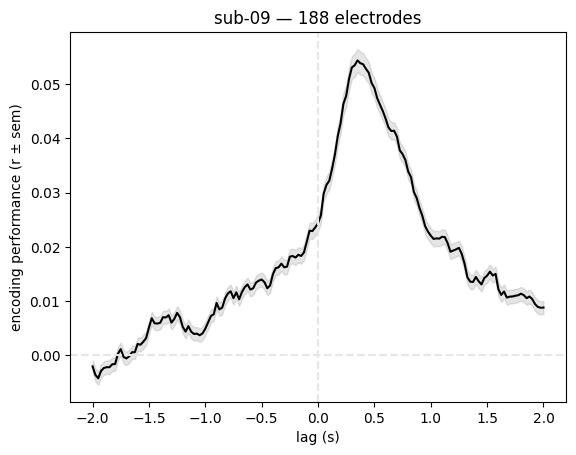

In [ ]:
#Plotting one patients glove correlation embedding

n_lags = corrs_embedding.shape[2]
lags   = np.linspace(-2.0, 2.0, n_lags)

mean = corrs_embedding.mean((0, 1))
err  = corrs_embedding.std((0, 1)) / np.sqrt(np.prod(corrs_embedding.shape[:2]))

fig, ax = plt.subplots()
ax.plot(lags, mean, color='black')
ax.fill_between(lags, mean - err, mean + err, alpha=0.1, color='black')
ax.axvline(0, c=(.9,.9,.9), ls="--")
ax.axhline(0, c=(.9,.9,.9), ls="--")
ax.set_xlabel("lag (s)")
ax.set_ylabel("encoding performance (r ± sem)")
ax.set_title(f"sub-{subj_id} — {corrs_embedding.shape[1]} electrodes")
plt.savefig(f"fig4a_sub{subj_id}.png", dpi=150, bbox_inches='tight')
plt.show()

## Three methods to select: Average in time window, average across all lags, maximum values across lags
Although all 3 methods were tested, averaging across the 161 lags was the method chosen because:
* It overlapped the most with the original 160 electrodes (see notebook 160 significant electrodes)
* Most electrodes found were in language brain area's, the other two methods had many more electrodes in non-language related areas such as the occular region

In [ ]:
################################## Sample t-test To chose electrodes
#######Method 1: Averaging across all correlations of lags that in the 0 to 500ms window, and then testing if that average correlation is significantly above 0 across folds



subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)
window_mask = (lags_ms >= 0) & (lags_ms <= 500)

all_sig_corrs   = []   # timecourses of significant electrodes
all_sig_elec    = []   # rows for the master dataframe

for sid in subject_ids:
    try:
        corrs    = np.load(f"corerlations_all{sid}.npy")
        elec_df  = pd.read_csv(f"electrodes_sub{sid}.csv")
    except FileNotFoundError:
        print(f"sub-{sid}: missing file, skipping")
        continue

    assert corrs.shape[1] == len(elec_df), \
        f"sub-{sid}: corrs has {corrs.shape[1]} electrodes but csv has {len(elec_df)}"

    # ── Significance test (average within that window)
    window_corrs    = corrs[:, :, window_mask].mean(axis=2)   # (folds, n_elec)
    t_stats, p_vals = stats.ttest_1samp(window_corrs, popmean=0, axis=0)
    p_vals          = p_vals / 2                               # one-tailed
    p_vals[t_stats < 0] = 1.0
    sig_mask, _     = fdrcorrection(p_vals, alpha=0.01)

    n_sig = sig_mask.sum()
    print(f"sub-{sid}: {n_sig} / {len(sig_mask)} electrodes significant")

    if n_sig > 0:
        # Keep timecourses for the plot
        all_sig_corrs.append(corrs[:, sig_mask, :])

        # Keep metadata rows for the significant electrodes only
        sig_rows = elec_df[sig_mask].copy()
        sig_rows["elec_idx"] = np.where(sig_mask)[0]  # index into original n_elec
        all_sig_elec.append(sig_rows)

# ── Build master dataframe ───────────────────────────────────────────────────
sig_elec_master = pd.concat(all_sig_elec, ignore_index=True)
sig_elec_master.to_csv("significant_electrodes_glove.csv", index=False)

print(f"\nTotal significant electrodes across all subjects: {len(sig_elec_master)}")
print(sig_elec_master)

sub-02: 2 / 90 electrodes significant
sub-03: 36 / 191 electrodes significant
sub-04: 15 / 77 electrodes significant
sub-05: 4 / 157 electrodes significant
sub-06: 48 / 166 electrodes significant
sub-07: 25 / 116 electrodes significant
sub-08: 16 / 72 electrodes significant
sub-09: 72 / 188 electrodes significant

Total significant electrodes across all subjects: 218
     subject ch_name      x_mni      y_mni      z_mni  elec_idx
0          2     PO2 -61.999999 -57.999998   0.500000         1
1          2     LF3 -54.000001  43.333333  11.333333        17
2          3    LGA9 -57.000000  46.000000   8.000000         7
3          3   LGA10 -59.000000  37.999999  13.000000         8
4          3   LGA32 -71.000002 -27.000001  22.000000        30
..       ...     ...        ...        ...        ...       ...
213        9   DAMT3 -29.600000 -11.200000 -11.200000       166
214        9   DPMT2 -34.666669 -28.666668  -6.666667       173
215        9    DPI2 -45.000002 -14.000000   8.000000 

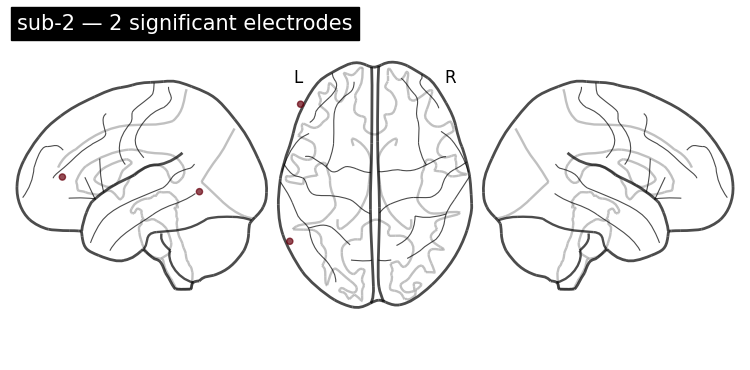

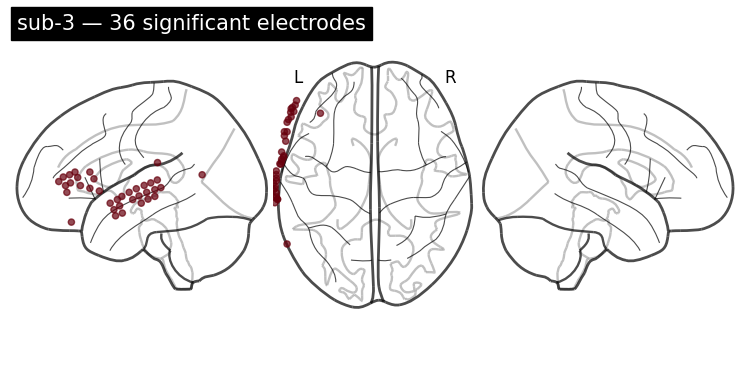

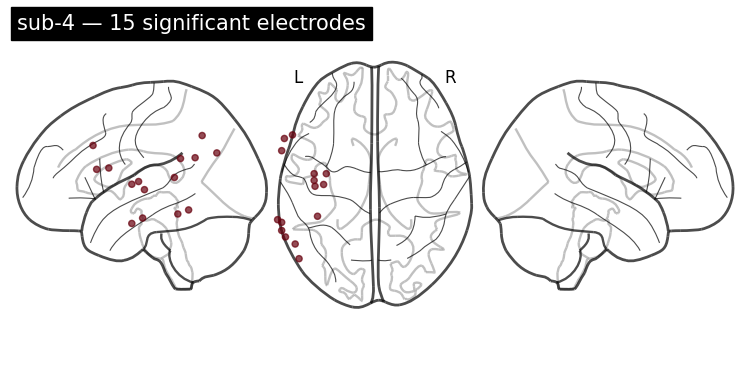

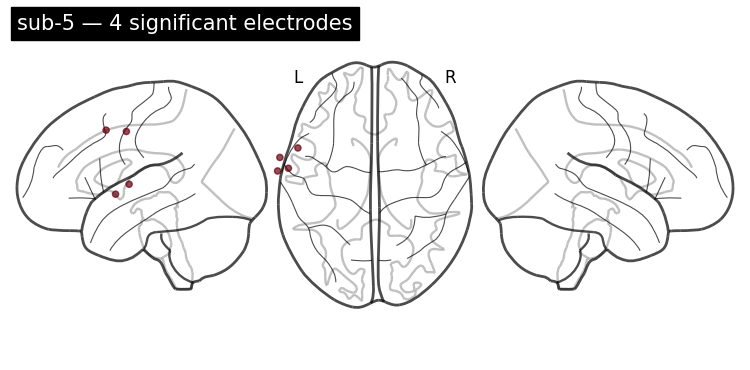

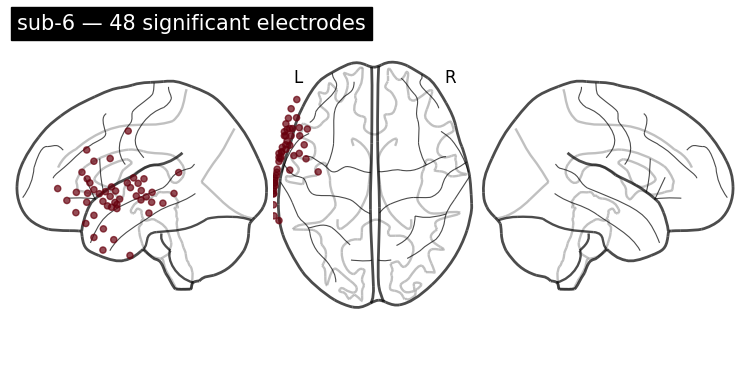

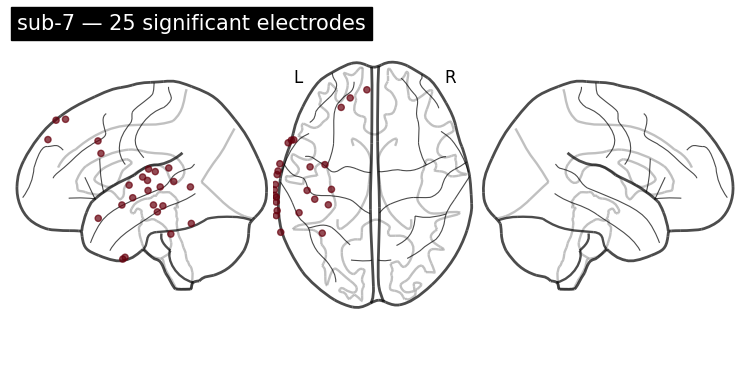

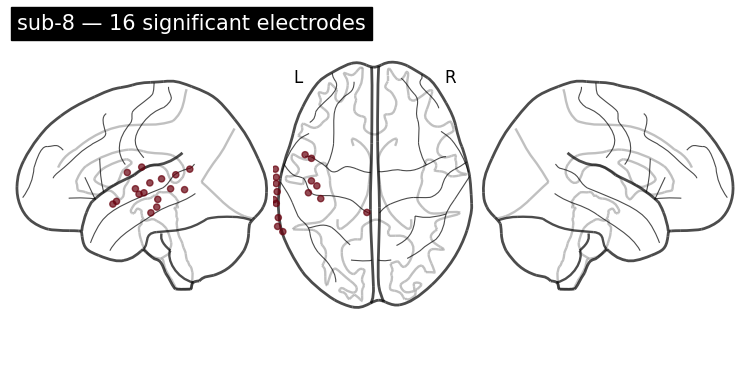

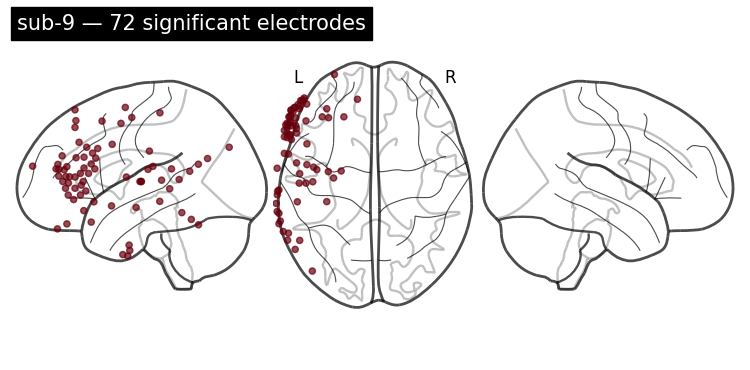

In [22]:
#Plotting those 218 significant electrodes on the brain, to see where they are located
for sid, group in sig_elec_master.groupby("subject"):
    coords_sub = group[["x_mni", "y_mni", "z_mni"]].values
    values_sub = np.ones(len(coords_sub))

    plot_markers(values_sub, coords_sub,
                 node_size=20,
                 display_mode='lzr',
                 node_cmap='Reds',
                 node_vmin=0, node_vmax=1,
                 colorbar=False,
                 title=f"sub-{sid} — {len(coords_sub)} significant electrodes")

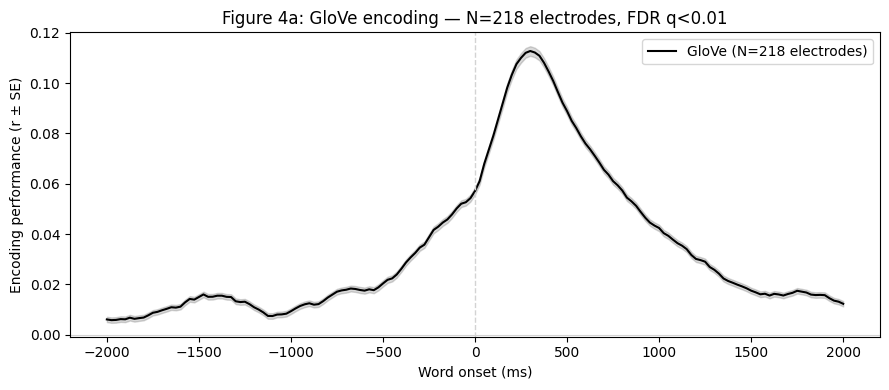

In [23]:
#Plotting what the glove embedding would look like:
all_pooled  = np.concatenate(all_sig_corrs, axis=1)   # (n_folds, total_sig, 161)
n_sig_total = all_pooled.shape[1]

mean = all_pooled.mean((0, 1))
err  = all_pooled.std((0, 1)) / np.sqrt(all_pooled.shape[0] * all_pooled.shape[1])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lags_ms, mean, color='black', linewidth=1.5,
        label=f'GloVe (N={n_sig_total} electrodes)')
ax.fill_between(lags_ms, mean - err, mean + err, alpha=0.15, color='black')
ax.axvline(0, color='lightgray', ls='--', lw=1)
ax.axhline(0, color='lightgray', ls='-',  lw=0.8)
ax.set_xlabel("Word onset (ms)")
ax.set_ylabel("Encoding performance (r ± SE)")
ax.set_title(f"Figure 4a: GloVe encoding — N={n_sig_total} electrodes, FDR q<0.01")
ax.legend()
plt.tight_layout()
plt.savefig("fig4a_all_subjects.png", dpi=150, bbox_inches='tight')
plt.show()

sub-02: 0 / 90 electrodes significant
sub-03: 41 / 191 electrodes significant
sub-04: 15 / 77 electrodes significant
sub-05: 3 / 157 electrodes significant
sub-06: 25 / 166 electrodes significant
sub-07: 19 / 116 electrodes significant
sub-08: 16 / 72 electrodes significant
sub-09: 55 / 188 electrodes significant

Total significant electrodes: 174
     subject ch_name      x_mni      y_mni      z_mni  elec_idx
0          3    LGA4 -59.000000  22.666667  34.666669         2
1          3    LGA7 -61.999999  -7.000000  48.000000         5
2          3   LGA10 -59.000000  37.999999  13.000000         8
3          3   LGA11 -62.399998  28.800000  18.800000         9
4          3   LGA19 -64.800002  24.800001   8.400000        17
..       ...     ...        ...        ...        ...       ...
169        9     AF6 -52.999999  46.000000  17.000001       159
170        9     IF4 -34.666669  39.999999 -23.333333       163
171        9   DAMT3 -29.600000 -11.200000 -11.200000       166
172       

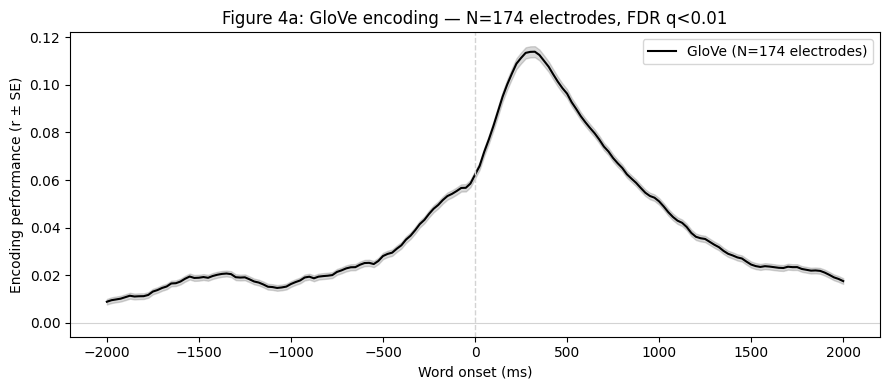

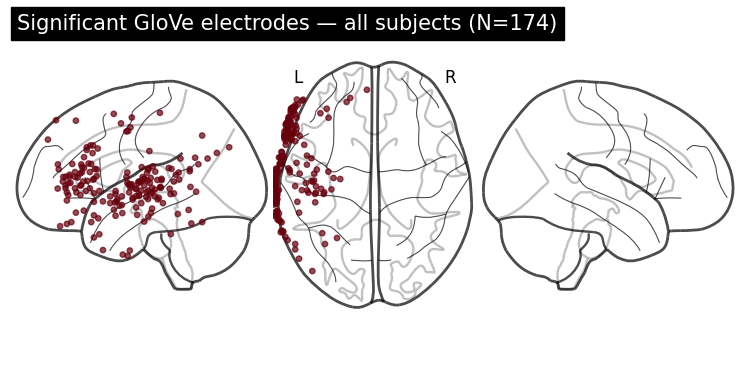

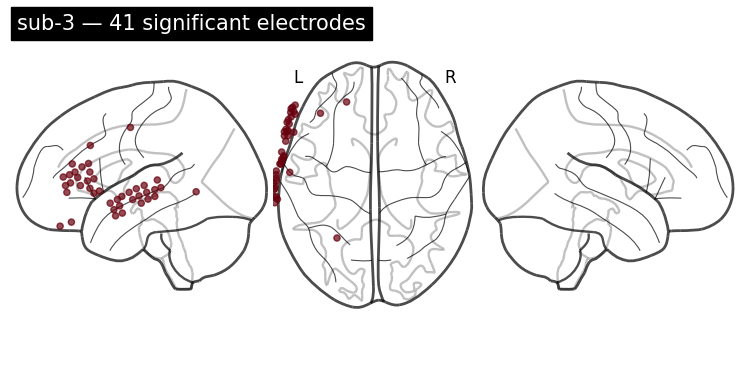

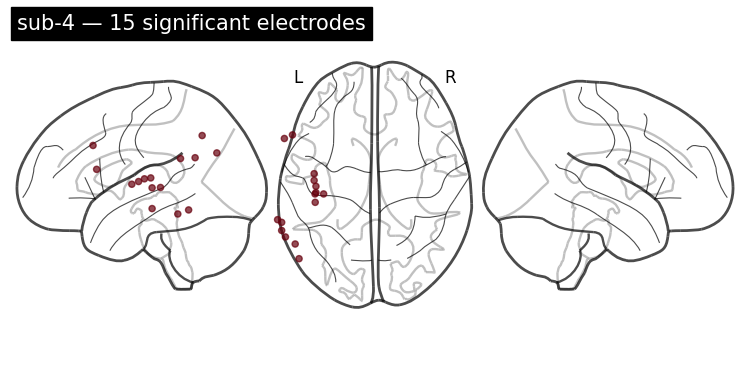

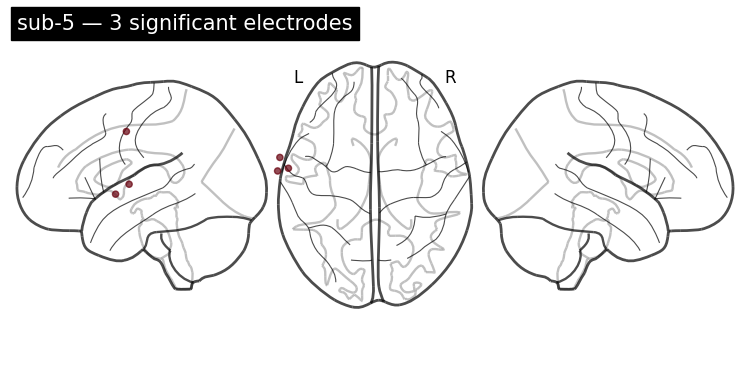

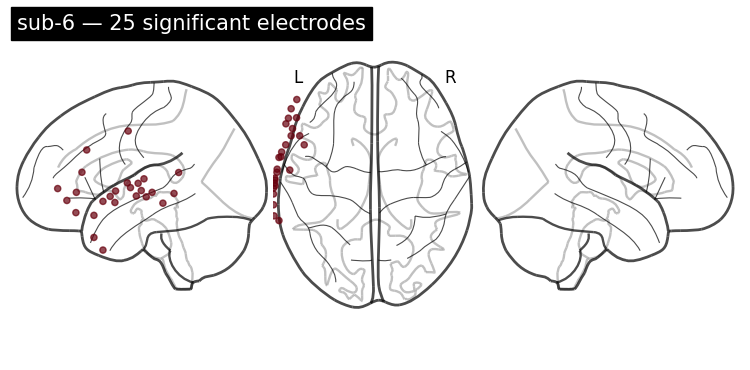

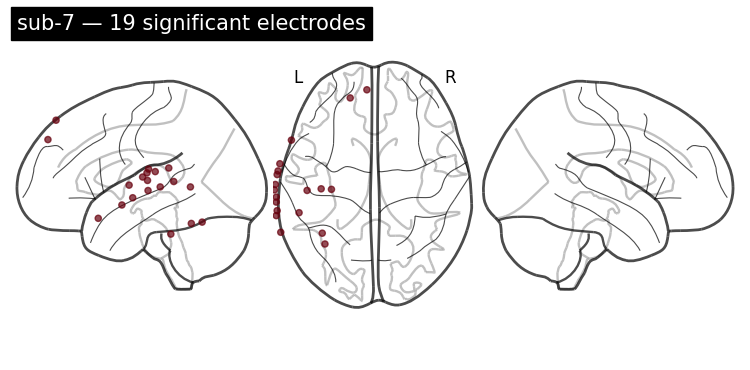

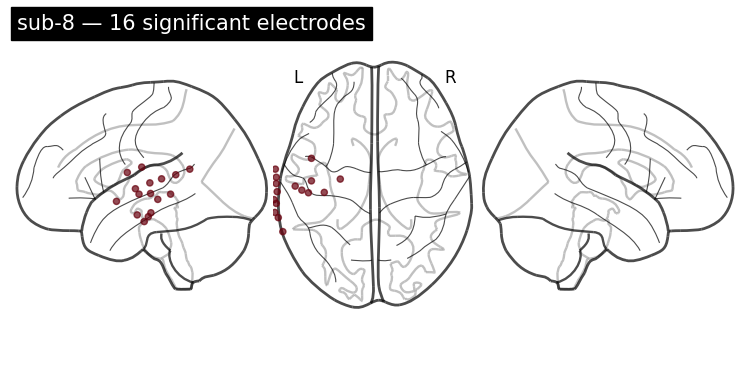

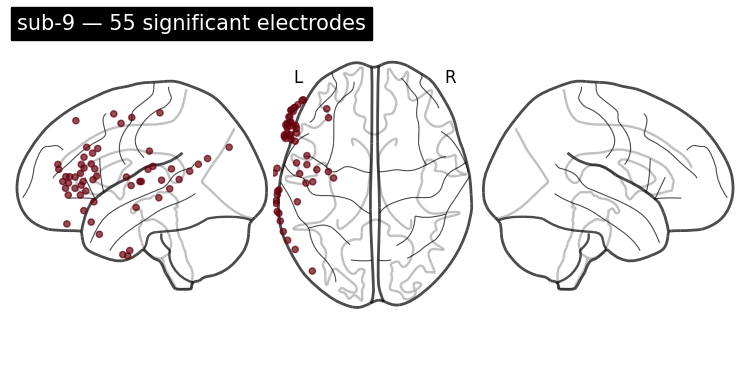

In [42]:
################################## Sample t-test To chose electrodes
#######Method 2: Averaging across all correlations of lags across folds
################# This was the final/chosen method


subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)

all_sig_corrs = []
all_sig_elec  = []

for sid in subject_ids:
    try:
        corrs   = np.load(f"corerlations_all{sid}.npy")   # (n_folds, n_elec, 161)
        elec_df = pd.read_csv(f"electrodes_sub{sid}.csv")
    except FileNotFoundError:
        print(f"sub-{sid}: missing file, skipping")
        continue

    assert corrs.shape[1] == len(elec_df), \
        f"sub-{sid}: corrs has {corrs.shape[1]} electrodes but csv has {len(elec_df)}"

    # ── Significance test: full-curve mean across all 161 lags ──────────────
    overall_per_fold        = corrs.mean(axis=2)           # (n_folds, n_elec)
    t_stats, p_vals         = stats.ttest_1samp(overall_per_fold, popmean=0, axis=0)
    p_vals                  = p_vals / 2                   # one-tailed
    p_vals[t_stats < 0]     = 1.0
    sig_mask, _             = fdrcorrection(p_vals, alpha=0.01, method='indep')

    n_sig = sig_mask.sum()
    print(f"sub-{sid}: {n_sig} / {len(sig_mask)} electrodes significant")

    if n_sig > 0:
        all_sig_corrs.append(corrs[:, sig_mask, :])

        sig_rows = elec_df[sig_mask].copy()
        sig_rows["elec_idx"] = np.where(sig_mask)[0]
        all_sig_elec.append(sig_rows)

sig_elec_master = pd.concat(all_sig_elec, ignore_index=True)
sig_elec_master.to_csv("significant_electrodes_glove.csv", index=False)
print(f"\nTotal significant electrodes: {len(sig_elec_master)}")
print(sig_elec_master)

all_pooled  = np.concatenate(all_sig_corrs, axis=1)   # (n_folds, total_sig, 161)
n_sig_total = all_pooled.shape[1]

mean = all_pooled.mean((0, 1))
err  = all_pooled.std((0, 1)) / np.sqrt(all_pooled.shape[0] * all_pooled.shape[1])

#Plotting the Glove ending 
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lags_ms, mean, color='black', linewidth=1.5,
        label=f'GloVe (N={n_sig_total} electrodes)')
ax.fill_between(lags_ms, mean - err, mean + err, alpha=0.15, color='black')
ax.axvline(0, color='lightgray', ls='--', lw=1)
ax.axhline(0, color='lightgray', ls='-',  lw=0.8)
ax.set_xlabel("Word onset (ms)")
ax.set_ylabel("Encoding performance (r ± SE)")
ax.set_title(f"Figure 4a: GloVe encoding — N={n_sig_total} electrodes, FDR q<0.01")
ax.legend()
plt.tight_layout()
plt.savefig("fig4a_all_subjects.png", dpi=150, bbox_inches='tight')
plt.show()

# Brain plot: all significant electrodes 
all_coords = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

plot_markers(np.ones(len(all_coords)), all_coords,
             node_size=15, display_mode='lzr',
             node_cmap='Reds', node_vmin=0, node_vmax=1,
             colorbar=False,
             title=f"Significant GloVe electrodes — all subjects (N={n_sig_total})")

# Brain plot: per subject 
for sid, group in sig_elec_master.groupby("subject"):
    coords_sub = group[["x_mni", "y_mni", "z_mni"]].values
    plot_markers(np.ones(len(coords_sub)), coords_sub,
                 node_size=20, display_mode='lzr',
                 node_cmap='Reds', node_vmin=0, node_vmax=1,
                 colorbar=False,
                 title=f"sub-{sid} — {len(coords_sub)} significant electrodes")

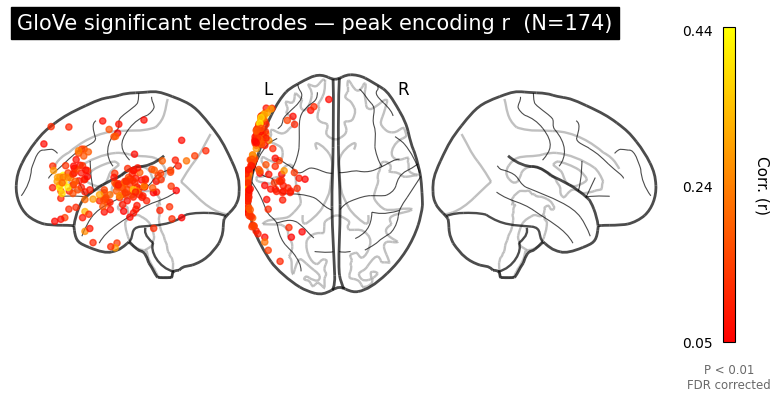

Saved. Peak r range: 0.053 – 0.437


In [55]:
######################## Ploting the ALL the final chosen electrodes 


# all_pooled : (n_folds, n_sig_electrodes, 161)
# Average across folds first -> (n_sig_electrodes, 161)
mean_per_elec = all_pooled.mean(axis=0)   # (n_sig, 161)
peak_corr     = mean_per_elec.max(axis=1) # (n_sig,)

coords = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

# Colormap: 'autumn' goes exactly red (low) → yellow (high)
cmap = plt.cm.autumn
vmin = peak_corr.min()   # minimum
vmax = peak_corr.max()   # maximum (your 0.437) #Alternatives you can clips to bottom or top 5 %, makes picture more clear

norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

display = plotting.plot_markers(
    node_values  = peak_corr,
    node_coords  = coords,
    node_size    = 20,
    node_cmap    = cmap,
    node_vmin    = vmin,
    node_vmax    = vmax,
    display_mode = "lzr",
    colorbar     = True,
    title        = f"GloVe significant electrodes — peak encoding r  (N={len(coords)})",
)

# Colorbar: show actual min, mid, max 
fig     = plt.gcf()
cbar_ax = fig.axes[-1]

mid = (vmin + vmax) / 2
cbar_ax.set_yticks([vmin, mid, vmax])
cbar_ax.set_yticklabels([f"{vmin:.2f}", f"{mid:.2f}", f"{vmax:.2f}"], fontsize=10)
cbar_ax.set_ylabel("Corr. (r)", fontsize=11, rotation=270, labelpad=14, va="bottom")

cbar_pos = cbar_ax.get_position()
fig.text(
    cbar_pos.x0 + cbar_pos.width / 2,
    cbar_pos.y0 - 0.06,
    "P < 0.01\nFDR corrected",
    ha="center", va="top", fontsize=8.5, color="dimgrey",
    transform=fig.transFigure,
)

plt.savefig("fig3c_brain_peak_corr.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved. Peak r range: {peak_corr.min():.3f} – {peak_corr.max():.3f}")

sub-02: 90 / 90 electrodes significant
sub-03: 191 / 191 electrodes significant
sub-04: 77 / 77 electrodes significant
sub-05: 157 / 157 electrodes significant
sub-06: 166 / 166 electrodes significant
sub-07: 116 / 116 electrodes significant
sub-08: 72 / 72 electrodes significant
sub-09: 188 / 188 electrodes significant

Total significant electrodes: 1057
      subject ch_name      x_mni      y_mni      z_mni  elec_idx
0           2     PO1 -64.666666 -50.999999 -10.666667         0
1           2     PO2 -61.999999 -57.999998   0.500000         1
2           2     PO3 -57.999998 -64.999998  10.000000         2
3           2     PO4 -55.142857 -69.142856  20.857142         3
4           2     PO5 -49.333334 -74.000001  28.666668         4
...       ...     ...        ...        ...        ...       ...
1052        9    DAI4 -52.666668  10.000000 -11.333333       183
1053        9    DPI1 -41.000001 -12.000000   8.000000       184
1054        9    DPI2 -45.000002 -14.000000   8.000000   

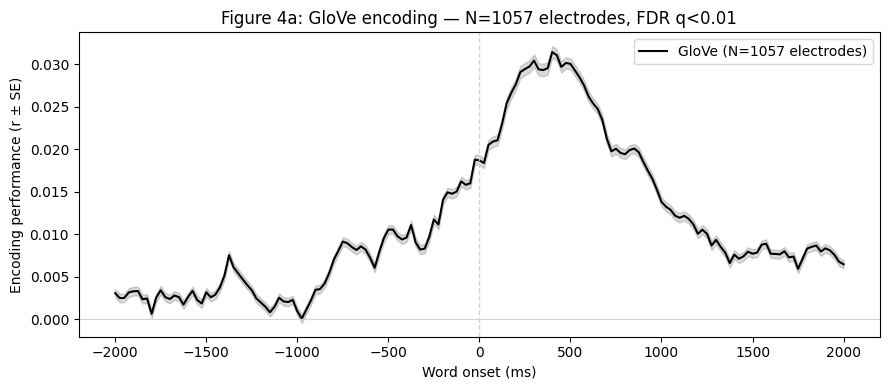

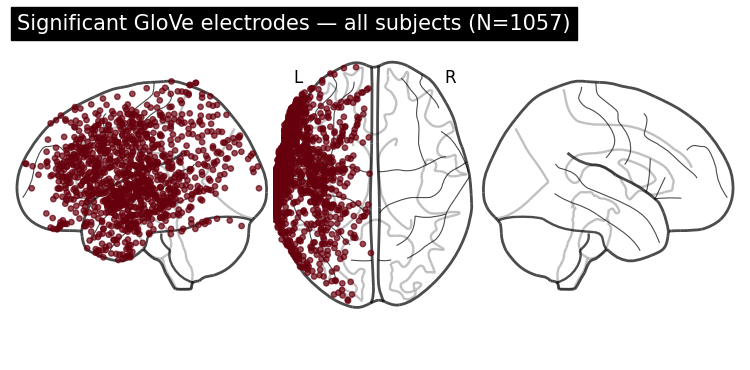

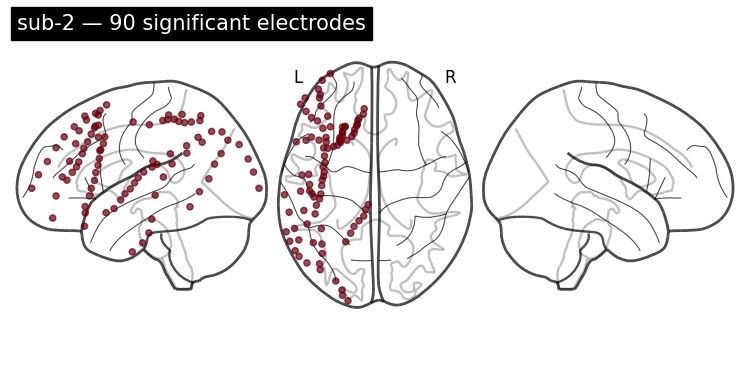

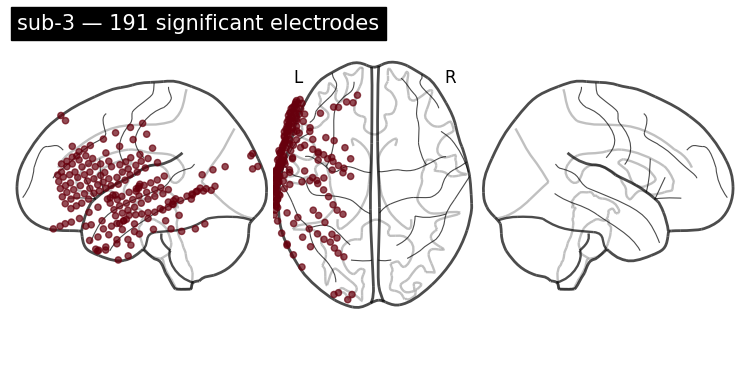

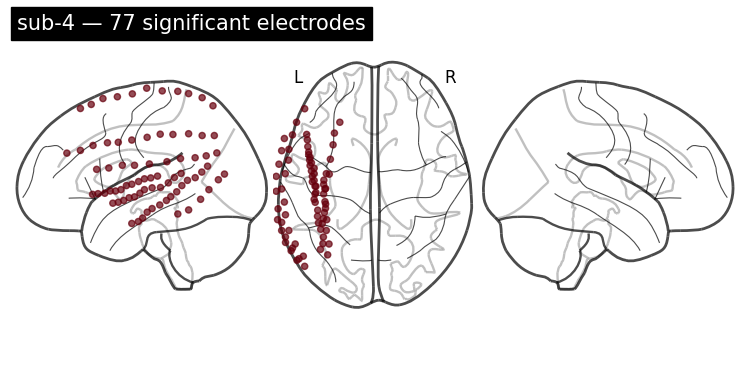

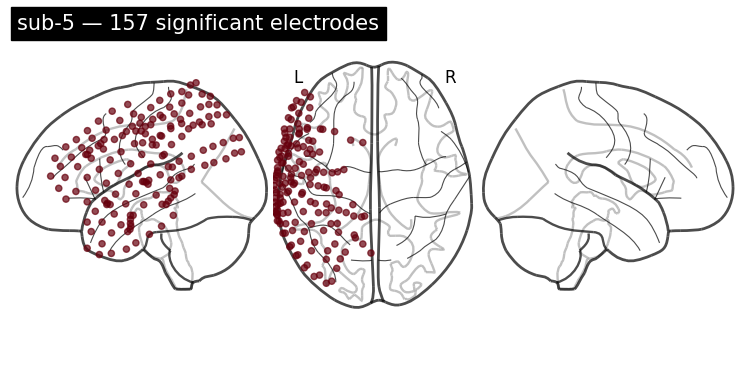

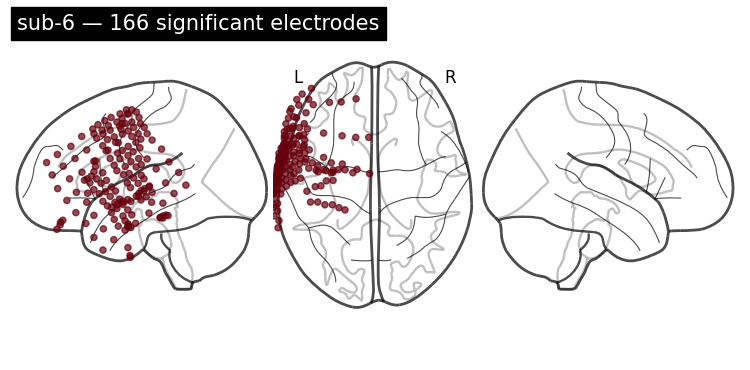

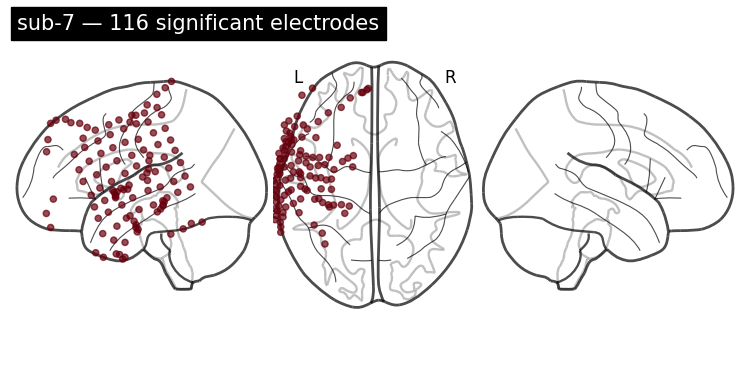

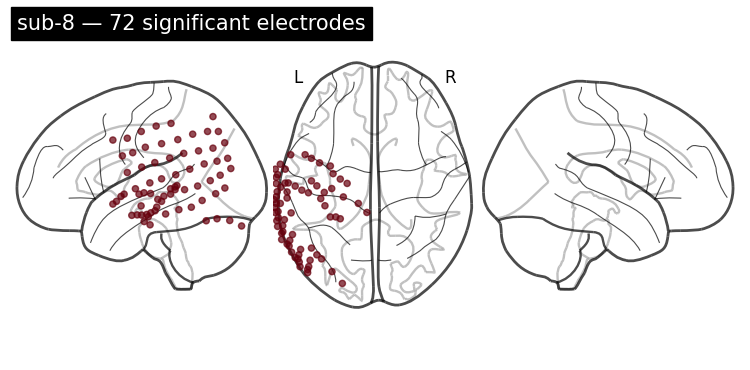

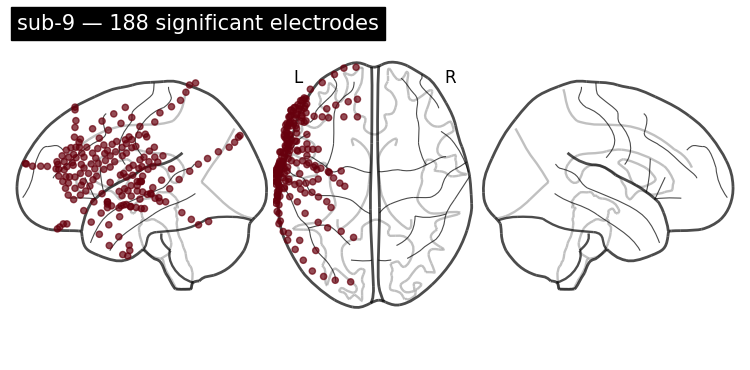

In [33]:
################################## Sample t-test To chose electrodes
#######Method 3: Taking the maximum across all correlations of lags across folds



subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)

all_sig_corrs = []
all_sig_elec  = []

for sid in subject_ids:
    try:
        corrs   = np.load(f"corerlations_all{sid}.npy")   # (n_folds, n_elec, 161)
        elec_df = pd.read_csv(f"electrodes_sub{sid}.csv")
    except FileNotFoundError:
        print(f"sub-{sid}: missing file, skipping")
        continue

    assert corrs.shape[1] == len(elec_df), \
        f"sub-{sid}: corrs has {corrs.shape[1]} electrodes but csv has {len(elec_df)}"

    # ── Significance test: MAX across all 161 lags ──────────────
    overall_per_fold        = corrs.max(axis=2)           # (n_folds, n_elec)
    t_stats, p_vals         = stats.ttest_1samp(overall_per_fold, popmean=0, axis=0)
    p_vals                  = p_vals / 2                   # one-tailed
    p_vals[t_stats < 0]     = 1.0
    sig_mask, _             = fdrcorrection(p_vals, alpha=0.01, method='indep')

    n_sig = sig_mask.sum()
    print(f"sub-{sid}: {n_sig} / {len(sig_mask)} electrodes significant")

    if n_sig > 0:
        all_sig_corrs.append(corrs[:, sig_mask, :])

        sig_rows = elec_df[sig_mask].copy()
        sig_rows["elec_idx"] = np.where(sig_mask)[0]
        all_sig_elec.append(sig_rows)

sig_elec_master = pd.concat(all_sig_elec, ignore_index=True)
sig_elec_master.to_csv("significant_electrodes_glove.csv", index=False)
print(f"\nTotal significant electrodes: {len(sig_elec_master)}")
print(sig_elec_master)

all_pooled  = np.concatenate(all_sig_corrs, axis=1)   # (n_folds, total_sig, 161)
n_sig_total = all_pooled.shape[1]

mean = all_pooled.mean((0, 1))
err  = all_pooled.std((0, 1)) / np.sqrt(all_pooled.shape[0] * all_pooled.shape[1])

#Plotting the Glove ending 
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lags_ms, mean, color='black', linewidth=1.5,
        label=f'GloVe (N={n_sig_total} electrodes)')
ax.fill_between(lags_ms, mean - err, mean + err, alpha=0.15, color='black')
ax.axvline(0, color='lightgray', ls='--', lw=1)
ax.axhline(0, color='lightgray', ls='-',  lw=0.8)
ax.set_xlabel("Word onset (ms)")
ax.set_ylabel("Encoding performance (r ± SE)")
ax.set_title(f"Figure 4a: GloVe encoding — N={n_sig_total} electrodes, FDR q<0.01")
ax.legend()
plt.tight_layout()
plt.savefig("fig4a_all_subjects.png", dpi=150, bbox_inches='tight')
plt.show()

# Brain plot: all significant electrodes 
all_coords = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

plot_markers(np.ones(len(all_coords)), all_coords,
             node_size=15, display_mode='lzr',
             node_cmap='Reds', node_vmin=0, node_vmax=1,
             colorbar=False,
             title=f"Significant GloVe electrodes — all subjects (N={n_sig_total})")

# Brain plot: per subject 
for sid, group in sig_elec_master.groupby("subject"):
    coords_sub = group[["x_mni", "y_mni", "z_mni"]].values
    plot_markers(np.ones(len(coords_sub)), coords_sub,
                 node_size=20, display_mode='lzr',
                 node_cmap='Reds', node_vmin=0, node_vmax=1,
                 colorbar=False,
                 title=f"sub-{sid} — {len(coords_sub)} significant electrodes")

# Figure 4 A)

In [ ]:
# Sanity Check:
# Loading the significant electrode table: it was created above, using the second method (Averaging across)
# total of 174 electrodes
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)
print(f"Total significant electrodes: {len(sig_elec_master)}")

Total significant electrodes: 174


In [57]:
sig_elec_master

,subject,ch_name,x_mni,y_mni,z_mni,elec_idx
0,03,LGA4,-59.000000,22.666667,34.666669,2
1,03,LGA7,-61.999999,-7.000000,48.000000,5
2,03,LGA10,-59.000000,37.999999,13.000000,8
3,03,LGA11,-62.399998,28.800000,18.800000,9
4,03,LGA19,-64.800002,24.800001,8.400000,17
...,...,...,...,...,...,...
169,09,AF6,-52.999999,46.000000,17.000001,159
170,09,IF4,-34.666669,39.999999,-23.333333,163
171,09,DAMT3,-29.600000,-11.200000,-11.200000,166
172,09,DPI2,-45.000002,-14.000000,8.000000,185


In [ ]:

#Full cell re-done

# 1)Loading the selected electrodes csv file for each subject
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)
print(f"Total significant electrodes: {len(sig_elec_master)}")

# 2) Shared setup details 
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)
EMB_DIM     = 50
alphas      = np.logspace(1, 10, 10)
inner_cv    = KFold(n_splits=5, shuffle=False)
model       = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)

# 3) The encoding model 
def train_encoding(X, Y, epochs_shape):
    corrs = []
    kfold = KFold(10, shuffle=False)
    for train_idx, test_idx in kfold.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        scaler  = StandardScaler()
        Y_train = scaler.fit_transform(Y_train)
        Y_test  = scaler.transform(Y_test)
        model.fit(X_train, Y_train)
        Y_pred  = model.predict(X_test)
        corr    = correlation_score(Y_test, Y_pred).reshape(epochs_shape)
        if "torch" in get_backend().__name__:
            corr = corr.numpy(force=True)
        corrs.append(corr)
    return np.stack(corrs)   # (n_folds, n_sig_elec, 161)

# 4) Per-patient loop 
all_corrs_arb  = []
all_corrs_rand = []

for sid in subject_ids: #each each patient

    # Check we have significant electrodes for this subject (extra test)
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        print(f"sub-{sid}: no significant electrodes, skipping")
        continue

    sig_indices = sub_sig["elec_idx"].values   # indices into the left-hemi raw (ONLY LEFT)
    print(f"\nsub-{sid}: {len(sig_indices)} significant electrodes → {sig_indices}")

    # Load raw and pick ONLY significant electrodes 
    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=sid, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

    # apply left-hemisphere filter 
    ch2loc    = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask   = coords_mm[:, 0] < 0
    lh_ch_names = [ch for ch, keep in zip(raw.ch_names, lh_mask) if keep]
    raw = raw.copy().pick(lh_ch_names)

    # pick only the significant electrodes by index
    sig_ch_names = [raw.ch_names[i] for i in sig_indices]
    raw = raw.copy().pick(sig_ch_names)
    print(f"  raw now has {len(raw.ch_names)} channels (significant only)")

    # Build epochs 
    sfreq  = raw.info['sfreq']
    events = np.zeros((len(df_glove), 3), dtype=int)
    events[:, 0] = (df_glove['start'].values * sfreq).astype(int)

    epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                        baseline=None, proj=False, event_id=None,
                        preload=True, event_repeated="merge")

    #  Window averaging → (n_words, n_sig_elec, 161)/ smoothing
    times        = epochs.times
    lag_centers  = np.arange(-2.0, 2.0 + 0.025/2, 0.025)
    WIN_HALF     = 0.100
    lag_masks    = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                    for τ in lag_centers]

    epochs_data   = epochs.get_data(copy=True)
    n_words, n_sig_elec, _ = epochs_data.shape
    epochs_shape  = (n_sig_elec, 161)

    epochs_windowed = np.stack(
        [epochs_data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
    ).astype(np.float32)

    Y = epochs_windowed.reshape(n_words, n_sig_elec * 161)

    # Align word embeddings to kept epochs
    df_final       = df_glove.iloc[epochs.selection]
    glove_emb_sel  = X_glove[epochs.selection]   # GloVe vectors for kept words
    n_words_kept   = len(df_final)

    if "torch" in get_backend().__name__:
        Y = Y.astype(np.float32)

########################################### CREATING ARBITARY EMBEDDINGS
    # Arbitrary embeddings 
    rng          = np.random.default_rng(seed=42)
    unique_words = df_final['word_clean'].unique()
    arb_dict     = {w: rng.uniform(-1, 1, EMB_DIM).astype('float32')
                    for w in unique_words}
    X_arb = np.stack([arb_dict[w] for w in df_final['word_clean']]).astype('float32')

    print(f"  Running arbitrary embeddings...")
    corrs_arb = train_encoding(X_arb, Y, epochs_shape)
    np.save(f"corrs_arb_{sid}.npy", corrs_arb)
    print(f"  Saved corrs_arb_{sid}.npy  shape: {corrs_arb.shape}")
    all_corrs_arb.append(corrs_arb)

    ######################################## Creating Random (shuffled GloVe) embeddings 
    rng2        = np.random.default_rng(seed=123)
    shuffle_idx = rng2.permutation(n_words_kept)
    X_rand      = glove_emb_sel[shuffle_idx].astype('float32')

    print(f"  Running random embeddings...")
    corrs_rand = train_encoding(X_rand, Y, epochs_shape)
    np.save(f"corrs_rand_{sid}.npy", corrs_rand)
    print(f"  Saved corrs_rand_{sid}.npy  shape: {corrs_rand.shape}")
    all_corrs_rand.append(corrs_rand)

# Final combined plot: all three curves 
# Load GloVe significant corrs (already computed, just reload them)
all_corrs_glove = []
for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        continue
    corrs_full = np.load(f"corerlations_all{sid}.npy")   # (folds, all_lh_elec, 161)
    sig_idx    = sub_sig["elec_idx"].values
    all_corrs_glove.append(corrs_full[:, sig_idx, :])


Total significant electrodes: 174
sub-02: no significant electrodes, skipping

sub-03: 41 significant electrodes → [  2   5   8   9  17  25  34  35  36  42  44  45  69  72  73  74  76  77
  78  80  84  85  86  94 106 110 111 112 113 114 115 117 118 119 120 121
 122 124 153 155 178]
  raw now has 41 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_03.npy  shape: (10, 41, 161)
  Running random embeddings...
  Saved corrs_rand_03.npy  shape: (10, 41, 161)

sub-04: 15 significant electrodes → [13 21 23 29 30 32 33 34 43 60 61 72 73 74 75]
  raw now has 15 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_04.npy  shape: (10, 15, 161)
  Running random embeddings...
  Saved corrs_rand_04.npy  shape: (10, 15, 161)

sub-05: 3 significant electrodes → [21 41 42]
  raw now has 3 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_05.npy  shape: (10, 3, 161)
  Running random embeddings...
  Saved corrs_rand_05.npy  shape: (10, 3, 161)

sub-06: 25 significant electrodes → [  5  14  20  21  22  28  32  41  50  52  57  58  59  61  62  73  98  99
 100 106 107 109 115 116 121]
  raw now has 25 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_06.npy  shape: (10, 25, 161)
  Running random embeddings...
  Saved corrs_rand_06.npy  shape: (10, 25, 161)

sub-07: 19 significant electrodes → [ 42  43  44  45  47  49  50  51  52  53  62  64  66  88  89  91 112 113
 114]
  raw now has 19 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_07.npy  shape: (10, 19, 161)
  Running random embeddings...
  Saved corrs_rand_07.npy  shape: (10, 19, 161)

sub-08: 16 significant electrodes → [12 13 18 19 20 21 22 29 30 54 62 63 64 67 69 71]
  raw now has 16 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_08.npy  shape: (10, 16, 161)
  Running random embeddings...
  Saved corrs_rand_08.npy  shape: (10, 16, 161)

sub-09: 55 significant electrodes → [  5  10  13  14  15  16  17  24  25  31  32  39  43  45  47  53  54  57
  58  59  64  72  73  74  76  77  78  79  81  82  83  87  88  89  90  92
 101 103 110 113 121 125 126 127 135 137 138 139 145 150 159 163 166 185
 186]
  raw now has 55 channels (significant only)
Not setting metadata
4867 matching events found
No baseline correction applied
Loading data for 4867 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_38705/1316913922.py:74: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  Running arbitrary embeddings...
  Saved corrs_arb_09.npy  shape: (10, 55, 161)
  Running random embeddings...
  Saved corrs_rand_09.npy  shape: (10, 55, 161)


In [ ]:
#### To build the asterisks from the figures i need to do Permutation/ swap procedure:

#1) Get all the saved correlation values across folds


#2) For every electrode, randomlyt swapp values between the abritary models results nad the glove one, then average the pairwise differences  
# Repeated step 2) will create a null dsibtruion we can use to determine a p-value 
# Must also use false discovery rate (FDR) correction (q < 0.01) to determine which lags it surpssed arbitary 

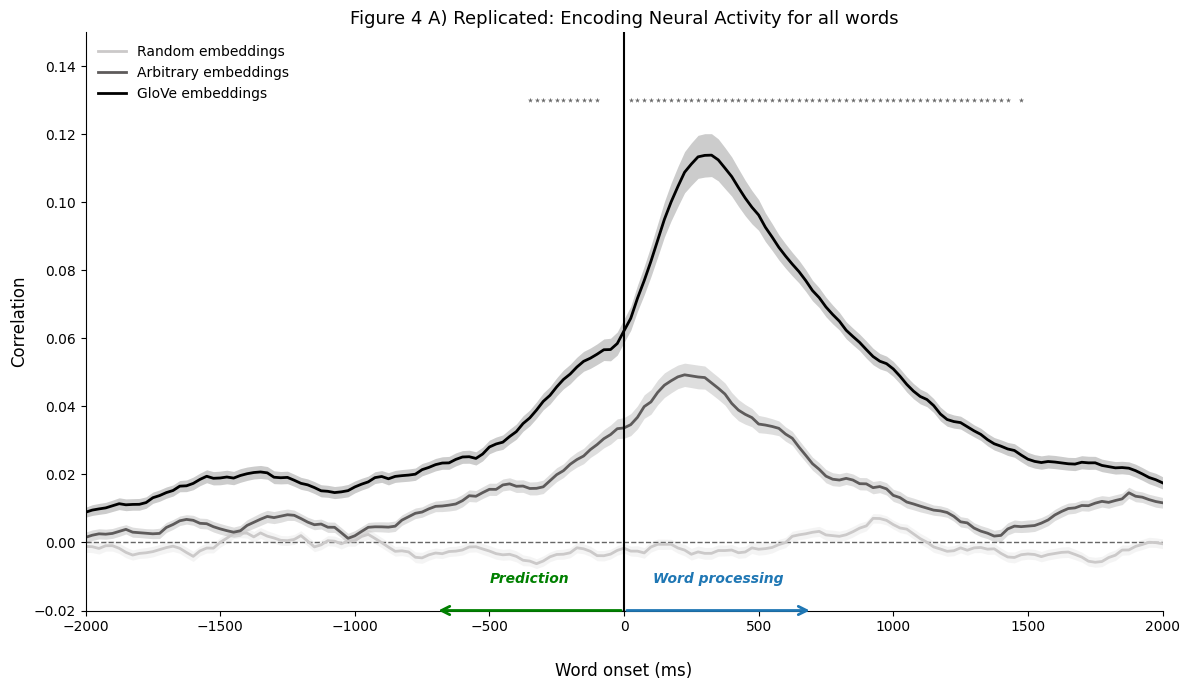

In [5]:
#################### plotting

lags_ms = np.linspace(-2000, 2000, 161)
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]

# Load electrode master list (load all the electrodes selected)
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

r_glove_list, r_arb_list, r_rand_list = [], [], []

for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0: continue
    sig_idx = sub_sig["elec_idx"].values
    try:
        #load all the correlation values found 
        ##g is for glove
        g = np.load(f"corerlations_all{sid}.npy")[:, sig_idx, :].mean(axis=0)
        ## a is for aribitray 
        a = np.load(f"corrs_arb_{sid}.npy").mean(axis=0)
        ## r is for random
        r = np.load(f"corrs_rand_{sid}.npy").mean(axis=0)
        
        r_glove_list.append(g)
        r_arb_list.append(a)
        r_rand_list.append(r)
    except FileNotFoundError:
        print(f"sub-{sid} files not found, skipping")

r_glove = np.concatenate(r_glove_list, axis=0)
r_arb   = np.concatenate(r_arb_list,   axis=0)
r_rand  = np.concatenate(r_rand_list,  axis=0)
N_elec  = r_glove.shape[0]

# PERMUTATION TEST for asterisks
diff        = r_glove - r_arb
actual_mean = diff.mean(axis=0)
pct_pos     = (diff > 0).mean(axis=0)

N_PERMS = 5000
rng     = np.random.default_rng(seed=0)

# Flip signs PER ELECTRODE
# Shape (N_PERMS, N_elec, 1) allows broadcasting across all 161 lags
#
signs_per_elec = rng.choice(np.array([-1, 1], dtype=np.float32), 
                            size=(N_PERMS, N_elec, 1))

# Generate null distribution of the mean difference
# randomly swaps values between glove and arbitrary 
null_dist = (signs_per_elec * diff[np.newaxis, :, :]).mean(axis=1)

# Calculate p-values (one-tailed: GloVe > Arb)-> One-tailed test
p_vals = np.array([(null_dist[:, t] >= actual_mean[t]).mean() for t in range(len(lags_ms))])

# SIGNIFICANCE CRITERIA 
# Apply FDR correction
sig_fdr, _ = fdrcorrection(p_vals, alpha=0.01)

# Combined criteria: FDR significant AND 74% majority threshold
# Significant only if:
## 1) The mean difference is statistically significant
## AND
## 2) At least 74% of electrodes individually show GloVe > Arbitrary
sig_final = sig_fdr & (pct_pos >= 0.76)

######################################### PLOTTING 
def make_plot(sig_lags):
    mean_glove = r_glove.mean(axis=0); se_glove = r_glove.std(axis=0) / np.sqrt(N_elec)
    mean_arb   = r_arb.mean(axis=0);   se_arb   = r_arb.std(axis=0)   / np.sqrt(N_elec)
    mean_rand  = r_rand.mean(axis=0);  se_rand  = r_rand.std(axis=0)  / np.sqrt(N_elec)

    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Plotting Lines and Shading
    colors = [("#cbc9c9", mean_rand, se_rand, "Random"), 
              ("#5E5B5B", mean_arb, se_arb, "Arbitrary"), 
              ("black", mean_glove, se_glove, "GloVe")]

    for col, m, s, lab in colors:
        ax.fill_between(lags_ms, m - s, m + s, color=col, alpha=0.2, linewidth=0)
        ax.plot(lags_ms, m, color=col, linewidth=2, label=f"{lab} embeddings")

    # Asterisks placement
    if sig_lags.any():
        ast_y = 0.13
        ax.scatter(lags_ms[sig_lags], np.full(sig_lags.sum(), ast_y),
                    marker="*", s=15, color="dimgrey", linewidths=0, zorder=10)

    #
    # Dotted Baseline at y=0
    ax.axhline(0, color="black", lw=1.0, ls="--", alpha=0.6, zorder=1)
    
    # Set the y-limit so the plot floor is at -0.02
    ax.set_ylim(-0.02, 0.15)
    
    ax.spines['bottom'].set_position(('data', -0.02))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Writing the ARROWS 
    # Green arrow: on the floor line (y=-0.02), from 0 to -700
    ax.annotate('', xy=(-700, -0.02), xytext=(0, -0.02),
                arrowprops=dict(arrowstyle='->', color='green', lw=2, mutation_scale=15))
    
    # Blue arrow: on the floor line (y=-0.02), from 0 to 700
    ax.annotate('', xy=(700, -0.02), xytext=(0, -0.02),
                arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=2, mutation_scale=15))

    # Labels placed between the 0 baseline and the -0.02 floor
    ax.text(-350, -0.012, "Prediction", color="green", style="italic", ha="center", fontweight='bold')
    ax.text(350, -0.012, "Word processing", color="#1f77b4", style="italic", ha="center", fontweight='bold')

    # Styling
    ax.axvline(0, color="black", lw=1.5)
    
    ax.set_xlim(-2000, 2000)
    ax.set_xlabel("Word onset (ms)", fontsize=12, labelpad=20)
    ax.set_ylabel("Correlation", fontsize=12)
    ax.set_title("Figure 4 A) Replicated: Encoding Neural Activity for all words" , fontsize=13)

    plt.legend(loc="upper left", frameon=False)
    plt.tight_layout()
    plt.savefig("fixed_plot.png", dpi=200)
    plt.savefig("Figure_4a_HighRes.pdf", format='pdf', bbox_inches='tight')
    plt.show()

make_plot(sig_final)